# MNIST Dataset

TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (60000, 28, 28)  Test shape: (10000, 28, 28)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1901 - loss: 2.2838 - val_accuracy: 0.4283 - val_loss: 2.2423
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.3908 - loss: 2.2058 - val_accuracy: 0.4378 - val_loss: 2.1613
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5162 - loss: 2.1136 - val_accuracy: 0.5762 - val_loss: 2.0493
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5833 - loss: 1.9811 - val_accuracy: 0.6329 - val_loss: 1.8894
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6288 - loss: 1.7994 - val_accuracy: 0.6589 - val_loss: 1.6831
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6663 - loss: 1.5871 - val_accuracy: 0.6901 - val_loss: 1.4661
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7029 - loss: 1.3815 - val_accuracy: 0.7291 - val_loss: 1.2729
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7338 - loss: 1.2055 - val_accuracy: 0

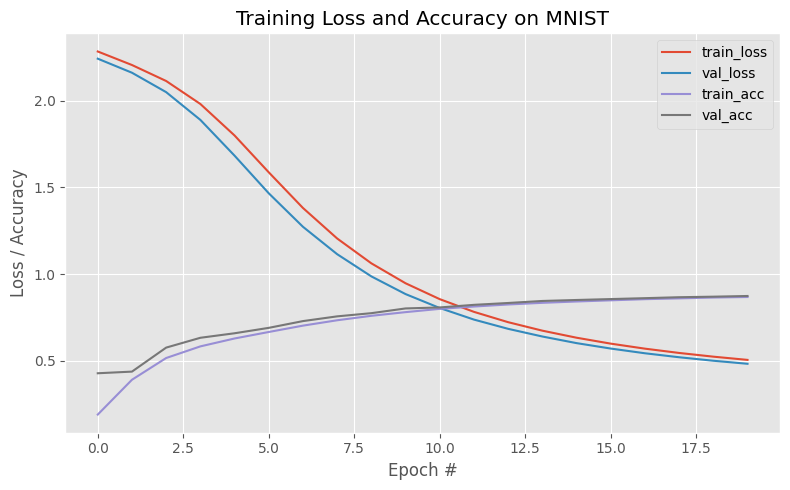

In [ ]:
# ================================================================
# FEEDFORWARD NEURAL NETWORK ON MNIST (train.csv / test.csv)
# ================================================================

# a. Import the necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/train.csv"     # change to your path
TEST_PATH = "/content/test.csv"       # change to your path

# b. Load the training and testing data
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

trainY = train_df["label"].values
testY = test_df["label"].values
trainX = train_df.drop(columns=["label"]).values    # 784 pixel columns
testX = test_df.drop(columns=["label"]).values

print("Train:", trainX.shape, " Test:", testX.shape)

# Scale pixels from 0-255 to 0-1
trainX = trainX.astype("float32") / 255.0
testX = testX.astype("float32") / 255.0

# Convert integer labels to one-hot vectors
lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

# c. Define the network architecture using Keras
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(10, activation="softmax"),
])
model.summary()

# d. Train the model using SGD with 11 epochs
model.compile(optimizer=SGD(learning_rate=0.01),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

H = model.fit(trainX, trainY,
              validation_split=0.1,
              epochs=11,
              batch_size=128,
              verbose=1)

# e. Evaluate the network
test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

predictions = model.predict(testX, verbose=0)
print("\nClassification Report:")
print(classification_report(testY.argmax(axis=1),
                            predictions.argmax(axis=1)))

# f. Plot the training loss and accuracy
epochs_range = range(1, len(H.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_range, H.history["loss"], label="train_loss")
ax1.plot(epochs_range, H.history["val_loss"], label="val_loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()
ax1.grid(True)

ax2.plot(epochs_range, H.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, H.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()
ax2.grid(True)

fig.suptitle("FNN Training History on MNIST")
plt.tight_layout()
plt.savefig("mnist_fnn_training.png", dpi=150)
plt.show()

In [ ]:
from tensorflow.keras import datasets, backend as K

K.clear_session()

((trainX, trainY), (testX, testY)) = datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print(trainY)

[5 0 4 ... 5 6 8]


In [ ]:
trainX = trainX.reshape((trainX.shape[0],784))
testX = testX.reshape((testX.shape[0],784))

In [ ]:
trainX = trainX.astype("float32") / 255.0
testX = testX.astype("float32") / 255.0

In [ ]:
from sklearn.preprocessing import LabelBinarizer

lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
model = Sequential([
  Input(shape=(784,)),
  Dense(256, activation="sigmoid"),
  Dense(128, activation="sigmoid"),
  Dense(10, activation="softmax")
])

In [ ]:
from tensorflow.keras.optimizers import SGD
sgd = SGD(learning_rate=0.01)
model.compile(loss="categorical_crossentropy",
              optimizer=sgd,
              metrics=["accuracy"])

In [ ]:
EPOCHS = 20
BATCH_SIZE = 128

In [ ]:
H = model.fit(trainX, trainY,
              # validation_data=(testX, testY),
              validation_split=0.2,
              epochs=EPOCHS,
              batch_size=BATCH_SIZE,
              verbose=1);

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8690 - loss: 0.4953 - val_accuracy: 0.8813 - val_loss: 0.4577
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8725 - loss: 0.4835 - val_accuracy: 0.8823 - val_loss: 0.4473
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8748 - loss: 0.4728 - val_accuracy: 0.8852 - val_loss: 0.4380
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8767 - loss: 0.4631 - val_accuracy: 0.8867 - val_loss: 0.4291
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8789 - loss: 0.4540 - val_accuracy: 0.8886 - val_loss: 0.4212
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8802 - loss: 0.4458 - val_accuracy: 0.8896 - val_loss: 0.4137
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8820 - loss: 0.4382 - val_accuracy: 0.8915 - val_loss: 0.4070
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8833 - loss: 0.4311 - val_accuracy:

In [ ]:
test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"Test Loss: {test_loss:.4f} Test accuracy: {test_acc:.4f}")

Test Loss: 0.3564 Test accuracy: 0.9012


In [ ]:
predictions = model.predict(testX, batch_size=BATCH_SIZE)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [ ]:
from sklearn.metrics import classification_report
print("Classification Report:")
print(classification_report(testY.argmax(axis=1),
                            predictions.argmax(axis=1),
                            target_names=[str(c) for c in lb.classes_]))

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       980
           1       0.96      0.97      0.96      1135
           2       0.89      0.88      0.88      1032
           3       0.89      0.89      0.89      1010
           4       0.89      0.92      0.90       982
           5       0.86      0.83      0.84       892
           6       0.92      0.92      0.92       958
           7       0.92      0.90      0.91      1028
           8       0.86      0.86      0.86       974
           9       0.89      0.87      0.88      1009

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print(H.history)

{'accuracy': [0.8690000176429749, 0.8724791407585144, 0.87479168176651, 0.8767083287239075, 0.8788750171661377, 0.8801666498184204, 0.8820000290870667, 0.8832916617393494, 0.8846041560173035, 0.8856041431427002, 0.8871666789054871, 0.8882708549499512, 0.8886666893959045, 0.8898541927337646, 0.8906458616256714, 0.8915208578109741, 0.8929166793823242, 0.8932916522026062, 0.8934583067893982, 0.8945000171661377], 'loss': [0.49534326791763306, 0.4835144579410553, 0.472797155380249, 0.46309491991996765, 0.4540274739265442, 0.4458259344100952, 0.4381552040576935, 0.43108096718788147, 0.42463943362236023, 0.41849300265312195, 0.41282856464385986, 0.40750831365585327, 0.40245160460472107, 0.3978855311870575, 0.3934516906738281, 0.3893515169620514, 0.3854003846645355, 0.381600022315979, 0.37806078791618347, 0.374716192483902], 'val_accuracy': [0.8812500238418579, 0.8823333382606506, 0.8851666450500488, 0.8866666555404663, 0.8885833621025085, 0.8895833492279053, 0.8914999961853027, 0.891583323478

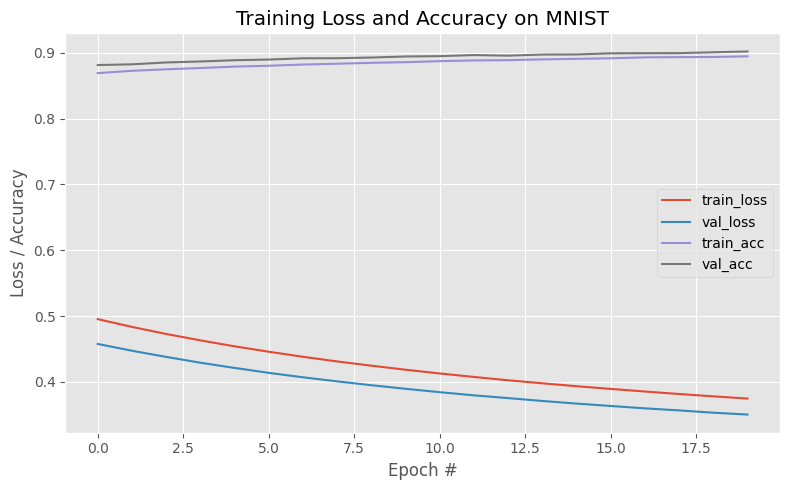

In [ ]:
N = np.arange(0, len(H.history["loss"]))
plt.style.use("ggplot")
plt.figure(figsize=(8,5))
plt.plot(N,H.history["loss"],label="train_loss")
plt.plot(N,H.history["val_loss"],label="val_loss")
plt.plot(N,H.history["accuracy"],label="train_acc")
plt.plot(N,H.history["val_accuracy"],label="val_acc")
plt.title("Training Loss and Accuracy on MNIST")
plt.xlabel("Epoch #")
plt.ylabel("Loss / Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# CIFAR10 Dataset

In [ ]:
# ================================================================
# FEEDFORWARD NEURAL NETWORK ON CIFAR-10 (cifar10.csv)
# ================================================================

# a. Import the necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "/content/cifar10.csv"     # change to your path

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# b. Load the data
df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)

label_col = "label" if "label" in df.columns else df.columns[0]
y = df[label_col].values.astype("int64")
pixel_cols = [c for c in df.columns if c != label_col and c.lower() != "id"]
X = df[pixel_cols].values.astype("float32")          # 3072 values per image
assert X.shape[1] == 3072, f"Expected 3072 pixel columns, found {X.shape[1]}"

# Split into train and test (80/20), keeping class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Scale pixels to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encode labels
lb = LabelBinarizer()
y_train_cat = lb.fit_transform(y_train)
y_test_cat = lb.transform(y_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

# c. Define the network architecture using Keras
model = Sequential([
    Input(shape=(3072,)),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(10, activation="softmax"),
])
model.summary()

# d. Train the model (SGD with momentum; swap in Adam if preferred)
model.compile(optimizer=SGD(learning_rate=0.01, momentum=0.9),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train_cat,
                    validation_split=0.1,
                    epochs=20,
                    batch_size=128,
                    verbose=1)

# e. Evaluate the network
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

# f. Plot the training loss and accuracy
epochs_range = range(1, len(history.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_range, history.history["loss"], label="train_loss")
ax1.plot(epochs_range, history.history["val_loss"], label="val_loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()
ax1.grid(True)

ax2.plot(epochs_range, history.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, history.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()
ax2.grid(True)

fig.suptitle("FNN Training History on CIFAR-10")
plt.tight_layout()
plt.savefig("cifar10_fnn_training.png", dpi=150)
plt.show()

TensorFlow version: 2.21.0
  1376256/170498071 ━━━━━━━━━━━━━━━━━━━━ 26:11 9us/step

KeyboardInterrupt: 

In [ ]:
from tensorflow.keras import datasets, backend as K

K.clear_session()

In [ ]:
((trainX, trainY),(testX, testY)) = datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2058s 12us/step


In [ ]:
trainX = trainX.reshape((trainX.shape[0],3072)).astype("float32") / 255.0
testX = trainY.reshape((testX.shape[0],3072)).astype("float32") / 255.0

In [ ]:
trainY = trainY.ravel()
testY = testY.ravel()

In [ ]:
from sklearn.preprocessing import LabelBinarizer

lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(3072,)),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(10, activation="softmax")
])

In [ ]:
from tensorflow.keras.optimizers import SGD

sgd = SGD(learning_rate=0.01)
model.compile(loss="categorical_crossentropy",
              optimizer=sgd,
              metrics=["accuracy"])

In [ ]:
EPOCHS = 20
BATCH_SIZE = 128

In [ ]:
H=model.fit(trainX, trainY,
          validation_split=0.2,
          epochs=EPOCHS,
          batch_size=BATCH_SIZE,
          verbose=1)

In [ ]:
test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"Test loss: {test_loss:.4f} Test accuracy: {test_acc:.4f}")

In [ ]:
predictions = model.predict(testX, batch_size=BATCH_SIZE)

In [ ]:
from sklearn.metrics import classification_report
print("Classification Report:")
print(classification_report(testY.argmax(axis=1),
                            predictions.argmax(axis=1),
                            target_names=["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]))

In [ ]:
N = np.arange(0, len(H.history["loss"]))
plt.style.use("ggplot")
plt.figure(figsize=(8,5))
plt.plot(N, H.history["loss"],label_name="train_loss")
plt.plot(N, H.history["val_loss"], label_name="val_loss")
plt.plot(N, H.history["acc"],label_name="train_acc")
plt.plot(N, H.history["val_acc"], label_name="val_acc")
plt.title("Training Loss and Accuracy on CIFAR-10")
plt.xlabel("Epoch #")
plt.ylabel("Loss / Accuracy")
plt.legend()
plt.tightlayout()
plt.show()

# Fashion MNIST


In [ ]:
# ================================================================
# FEEDFORWARD NEURAL NETWORK ON FASHION-MNIST (CSV)
# ================================================================

# a. Import the necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/fashion-mnist_train.csv"   # change to your path
TEST_PATH = "/content/fashion-mnist_test.csv"     # change to your path

CLASS_NAMES = ["T-shirt-top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# b. Load the training and testing data
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

trainY = train_df["label"].values
testY = test_df["label"].values
trainX = train_df.drop(columns=["label"]).values.astype("float32") / 255.0
testX = test_df.drop(columns=["label"]).values.astype("float32") / 255.0

lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

# c. Define the network architecture using Keras
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(10, activation="softmax"),
])
model.summary()

# d. Train the model using SGD
model.compile(optimizer=SGD(learning_rate=0.01),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

H = model.fit(trainX, trainY,
              validation_split=0.1,
              epochs=10,
              batch_size=128,
              verbose=1)

# e. Evaluate the network
test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

predictions = model.predict(testX, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(testY.argmax(axis=1), predictions,
                            target_names=CLASS_NAMES))

# f. Plot the training loss and accuracy
epochs_range = range(1, len(H.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_range, H.history["loss"], label="train_loss")
ax1.plot(epochs_range, H.history["val_loss"], label="val_loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True)

ax2.plot(epochs_range, H.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, H.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True)

fig.suptitle("FNN Training History on Fashion-MNIST")
plt.tight_layout()
plt.savefig("fashion_mnist_fnn_training.png", dpi=150)
plt.show()

# Sign language MNIST

In [ ]:
# ================================================================
# FEEDFORWARD NEURAL NETWORK ON SIGN LANGUAGE MNIST (train.csv / test.csv)
# ================================================================

# a. Import the necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TRAIN_PATH = "/content/train.csv"     # change to your path
TEST_PATH = "/content/test.csv"       # change to your path

# b. Load the training and testing data
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

trainY_raw = train_df["label"].values
testY_raw = test_df["label"].values
trainX = train_df.drop(columns=["label"]).values.astype("float32") / 255.0
testX = test_df.drop(columns=["label"]).values.astype("float32") / 255.0

# Labels are not continuous (9 and 25 are missing), so use LabelBinarizer
# and read the number of classes from the data, not a fixed number
lb = LabelBinarizer()
trainY = lb.fit_transform(trainY_raw)
testY = lb.transform(testY_raw)
NUM_CLASSES = len(lb.classes_)                       # should be 24

# Map each class position back to its letter.
# lb.classes_ holds the original label values, e.g. [0,1,...,8,10,...,24]
LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"                 # no J or Z
label_to_letter = dict(zip(lb.classes_, LETTERS))
class_names = [label_to_letter[c] for c in lb.classes_]

print("Train:", trainX.shape, " Test:", testX.shape)
print("Number of classes:", NUM_CLASSES)

# c. Define the network architecture using Keras
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

# d. Train the model using SGD
model.compile(optimizer=SGD(learning_rate=0.01),
              loss="categorical_crossentropy",
              metrics=["accuracy"])

H = model.fit(trainX, trainY,
              validation_split=0.1,
              epochs=10,
              batch_size=128,
              verbose=1)

# e. Evaluate the network
test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"\nTest loss: {test_loss:.4f}   Test accuracy: {test_acc:.4f}")

predictions = model.predict(testX, verbose=0).argmax(axis=1)
print("\nClassification Report:")
print(classification_report(testY.argmax(axis=1), predictions,
                            target_names=class_names))

# f. Plot the training loss and accuracy
epochs_range = range(1, len(H.history["loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(epochs_range, H.history["loss"], label="train_loss")
ax1.plot(epochs_range, H.history["val_loss"], label="val_loss")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True)

ax2.plot(epochs_range, H.history["accuracy"], label="train_acc")
ax2.plot(epochs_range, H.history["val_accuracy"], label="val_acc")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True)

fig.suptitle("FNN Training History on Sign Language MNIST")
plt.tight_layout()
plt.savefig("sign_mnist_fnn_training.png", dpi=150)
plt.show()